In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("aha.csv")

# Display the first five rows
df.head()


,region,region_code,period,pct_hospitals_cehrt,pct_hospitals_cehrt_2015,pct_hospitals_find_clinical_info,pct_hospitals_send_clinical_info,pct_hospitals_receive_clinical_info,pct_hospitals_integrate_scr,pct_hospitals_send_receive_find_integrate,...,pct_hospitals_share_labs_any_outside_provs,pct_hospitals_share_labs_any_outside_hospitals,pct_hospitals_share_labs_any_outside_ambu_provs,pct_hospitals_patients_ecopy_ehr,pct_hospitals_patients_ecopy_discharge_instr,pct_hospitals_share_care_summaries_any_outside_provs,pct_hospitals_share_care_summaries_any_outside_hospitals,pct_hospitals_share_care_summaries_any_outside_ambu_provs,pct_hospitals_patients_secure_message,pct_hospitals_integrate_any_clinical_info
0,National,US,2020,0.9375,0.8699,0.8038,0.9107,0.8466,0.7389,0.6235,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Alaska,AK,2020,1.0000,0.8459,1.0000,1.0000,1.0000,0.8459,0.8459,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Alabama,AL,2020,0.9404,0.8718,0.6924,0.9670,0.8360,0.5294,0.4571,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Arkansas,AR,2020,0.9186,0.8869,0.6630,0.9279,0.7460,0.6732,0.4916,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Arizona,AZ,2020,0.9149,0.9149,0.7638,0.9649,0.9406,0.8307,0.7395,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:

# Number of rows and columns
print("Dataset shape:", df.shape)

# Column names and data types
df.info()

# Display all column names
print(df.columns.tolist())


Dataset shape: (624, 42)
<class 'pandas.DataFrame'>
RangeIndex: 624 entries, 0 to 623
Data columns (total 42 columns):
 #   Column                                                     Non-Null Count  Dtype  
---  ------                                                     --------------  -----  
 0   region                                                     624 non-null    str    
 1   region_code                                                624 non-null    str    
 2   period                                                     624 non-null    int64  
 3   pct_hospitals_cehrt                                        264 non-null    float64
 4   pct_hospitals_cehrt_2015                                   156 non-null    float64
 5   pct_hospitals_find_clinical_info                           259 non-null    float64
 6   pct_hospitals_send_clinical_info                           259 non-null    float64
 7   pct_hospitals_receive_clinical_info                        259 non-null    float64
 

In [4]:

# Missing values by column
missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": df.isna().mean() * 100
})

missing.sort_values(
    "Missing Percentage",
    ascending=False
)


,Missing Count,Missing Percentage
pct_critical_access_hospitals_basic_ehr_no_notes,578,92.628205
pct_cah_hospitals_cehrt,577,92.467949
pct_hospitals_integrate_data_pdmp,577,92.467949
pct_critical_access_hospitals_basic_ehr_notes,574,91.987179
pct_hospitals_integrate_any_clinical_info,572,91.666667
pct_small_rural_hospitals_cehrt,572,91.666667
pct_hospitals_integrate_pdmp,522,83.653846
pct_hospitals_patients_ecopy_discharge_instr,521,83.493590
pct_hospitals_patients_secure_message,520,83.333333
pct_hospitals_patients_ecopy_ehr,472,75.641026


In [5]:
# Select the main EHR adoption indicators
ehr_columns = [
    "pct_hospitals_basic_ehr_no_notes",
    "pct_hospitals_basic_ehr_notes",
    "pct_hospitals_cehrt"
]

# Count available observations for each year
yearly_availability = (
    df.groupby("period")[ehr_columns]
      .count()
)

print(yearly_availability)

        pct_hospitals_basic_ehr_no_notes  pct_hospitals_basic_ehr_notes  \
period                                                                    
2008                                  51                              0   
2009                                  52                              0   
2010                                  52                              0   
2011                                  52                             52   
2012                                  52                             52   
2013                                  52                             52   
2014                                  52                             52   
2015                                  52                             52   
2017                                   0                              0   
2018                                   0                              0   
2019                                   0                              0   
2020                     

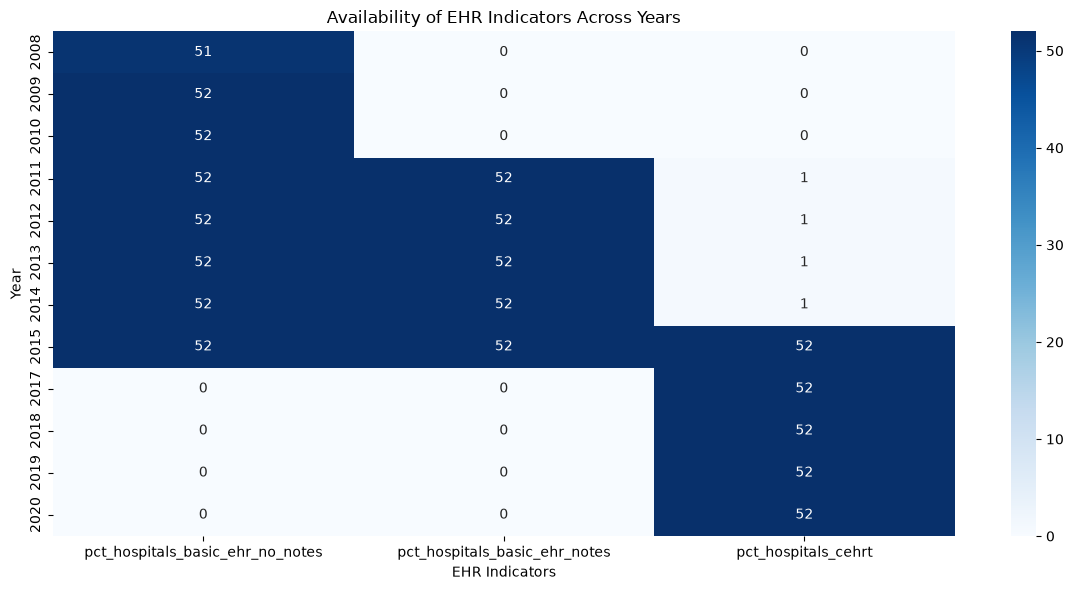

In [6]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    yearly_availability,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Availability of EHR Indicators Across Years")
plt.xlabel("EHR Indicators")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

In [7]:
# Create a state-level working dataset
df_states = df[df["region_code"] != "US"].copy()

print("State-level dataset shape:", df_states.shape)

# Check available years
print(sorted(df_states["period"].unique()))

# Check the number of regions
print(df_states["region_code"].nunique())

State-level dataset shape: (612, 42)
[np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020)]
51


In [8]:
# Exclude the national aggregate
df_states = df[df["region_code"] != "US"].copy()

# Select years with available basic EHR adoption data
ehr_data = df_states[
    df_states["period"].between(2008, 2015)
].copy()

# Calculate descriptive statistics by year
yearly_stats = (
    ehr_data.groupby("period")["pct_hospitals_basic_ehr_no_notes"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(4)
)

yearly_stats

,count,mean,median,std,min,max
period,,,,,,
2008,50,0.1452,0.130,0.0840,0.010,0.49
2009,51,0.1639,0.160,0.0801,0.030,0.36
2010,51,0.2025,0.210,0.0886,0.070,0.45
2011,51,0.3488,0.350,0.1389,0.070,0.67
2012,51,0.5669,0.580,0.1414,0.120,1.00
2013,51,0.7088,0.730,0.1299,0.320,0.92
2014,51,0.8341,0.860,0.0993,0.550,1.00
2015,51,0.8744,0.887,0.0783,0.654,1.00


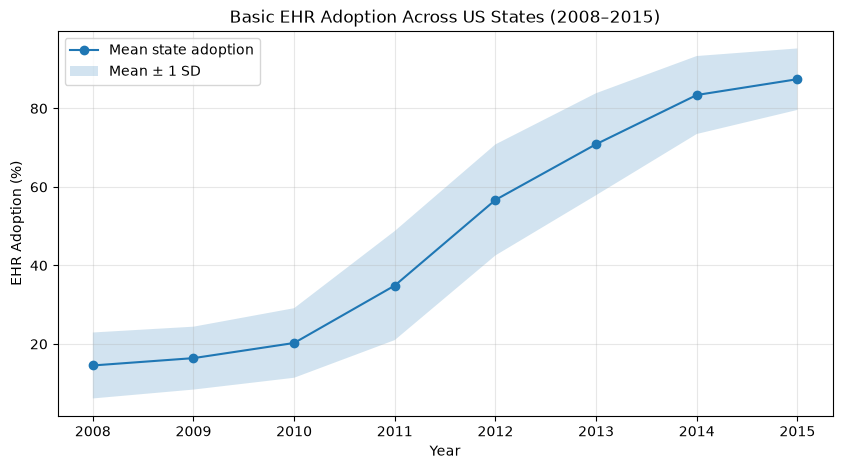

In [9]:
plt.figure(figsize=(10, 5))

plt.plot(
    yearly_stats.index,
    yearly_stats["mean"] * 100,
    marker="o",
    label="Mean state adoption"
)

plt.fill_between(
    yearly_stats.index,
    (yearly_stats["mean"] - yearly_stats["std"]) * 100,
    (yearly_stats["mean"] + yearly_stats["std"]) * 100,
    alpha=0.2,
    label="Mean ± 1 SD"
)

plt.xlabel("Year")
plt.ylabel("EHR Adoption (%)")
plt.title("Basic EHR Adoption Across US States (2008–2015)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [10]:

from scipy.stats import ttest_rel

# Select adoption data for 2008 and 2015
paired_data = (
    df_states[
        df_states["period"].isin([2008, 2015])
    ]
    .pivot(
        index="region_code",
        columns="period",
        values="pct_hospitals_basic_ehr_no_notes"
    )
    .dropna()
)

# Perform paired t-test
t_stat, p_value = ttest_rel(
    paired_data[2015],
    paired_data[2008],
    alternative="greater"
)

print("Number of paired regions:", len(paired_data))
print("Mean change (percentage points):",
      (paired_data[2015] - paired_data[2008]).mean() * 100)
print("T-statistic:", t_stat)
print("P-value:", p_value)


Number of paired regions: 50
Mean change (percentage points): 72.665882486
T-statistic: 49.370611221733945
P-value: 9.458382845311318e-44


In [11]:

from scipy import stats
import numpy as np

# Calculate within-state changes
differences = paired_data[2015] - paired_data[2008]

# Descriptive statistics of the differences
mean_diff = differences.mean()
sd_diff = differences.std(ddof=1)
n = len(differences)

# Standard error
se_diff = sd_diff / np.sqrt(n)

# 95% confidence interval
t_critical = stats.t.ppf(0.975, df=n-1)

ci_lower = mean_diff - t_critical * se_diff
ci_upper = mean_diff + t_critical * se_diff

print(f"Mean change: {mean_diff * 100:.2f} percentage points")
print(f"SD of changes: {sd_diff * 100:.2f} percentage points")
print(f"Standard error: {se_diff * 100:.2f} percentage points")
print(f"95% CI: [{ci_lower * 100:.2f}, {ci_upper * 100:.2f}] percentage points")


Mean change: 72.67 percentage points
SD of changes: 10.41 percentage points
Standard error: 1.47 percentage points
95% CI: [69.71, 75.62] percentage points


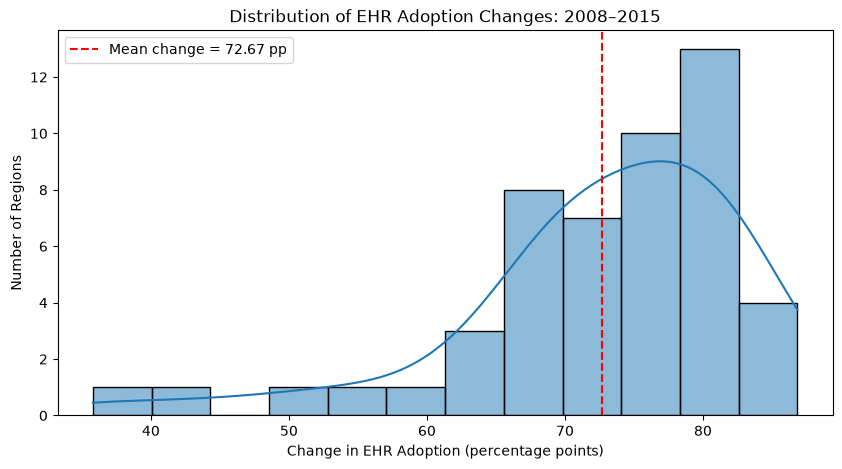

In [12]:

plt.figure(figsize=(10, 5))

sns.histplot(
    differences * 100,
    bins=12,
    kde=True
)

plt.axvline(
    mean_diff * 100,
    linestyle="--",
    color="red",
    label=f"Mean change = {mean_diff * 100:.2f} pp"
)

plt.xlabel("Change in EHR Adoption (percentage points)")
plt.ylabel("Number of Regions")
plt.title("Distribution of EHR Adoption Changes: 2008–2015")
plt.legend()
plt.show()


In [13]:

from scipy.stats import pearsonr, spearmanr

# Initial adoption and subsequent change
initial_adoption = paired_data[2008]
adoption_change = paired_data[2015] - paired_data[2008]

# Pearson correlation
pearson_r, pearson_p = pearsonr(
    initial_adoption,
    adoption_change
)

# Spearman correlation
spearman_r, spearman_p = spearmanr(
    initial_adoption,
    adoption_change
)

print(f"Pearson correlation: {pearson_r:.4f}")
print(f"Pearson p-value: {pearson_p:.6f}")

print(f"Spearman correlation: {spearman_r:.4f}")
print(f"Spearman p-value: {spearman_p:.6f}")


Pearson correlation: -0.6841
Pearson p-value: 0.000000
Spearman correlation: -0.5261
Spearman p-value: 0.000087


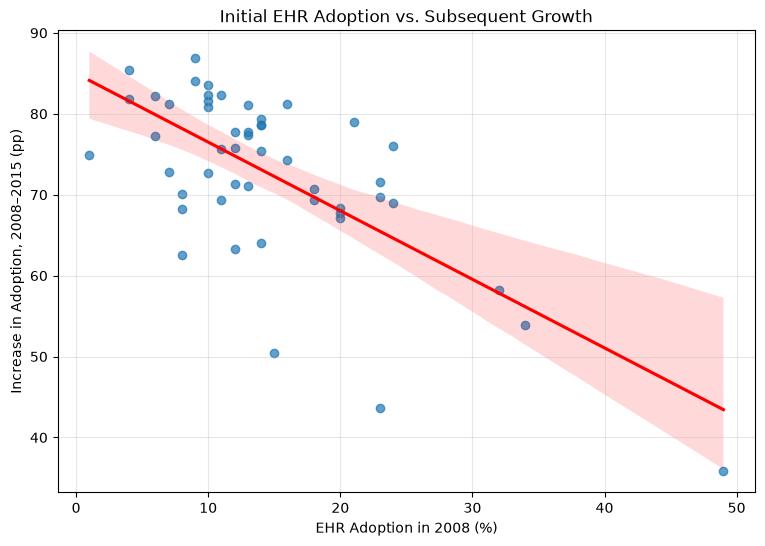

In [14]:

plt.figure(figsize=(9, 6))

sns.regplot(
    x=initial_adoption * 100,
    y=adoption_change * 100,
    scatter_kws={"alpha": 0.7},
    line_kws={"color": "red"}
)

plt.xlabel("EHR Adoption in 2008 (%)")
plt.ylabel("Increase in Adoption, 2008–2015 (pp)")
plt.title("Initial EHR Adoption vs. Subsequent Growth")
plt.grid(alpha=0.3)
plt.show()


In [15]:

import pandas as pd
import numpy as np

# Start with a copy of the original dataset
ehr_clean = df.copy()

# Standardize identifiers
ehr_clean["region_code"] = (
    ehr_clean["region_code"].astype(str).str.strip().str.upper()
)

ehr_clean["period"] = pd.to_numeric(
    ehr_clean["period"], errors="coerce"
)

# Exclude national aggregate
ehr_clean = ehr_clean[
    ehr_clean["region_code"] != "US"
].copy()

# Check for duplicate state-year records
duplicates = ehr_clean.duplicated(
    subset=["region_code", "period"]
).sum()

print("Duplicate state-year records:", duplicates)

# Select our historical basic EHR indicator
ehr_panel = ehr_clean[
    ehr_clean["period"].between(2008, 2015)
][[
    "region",
    "region_code",
    "period",
    "pct_hospitals_basic_ehr_no_notes"
]].copy()

# Rename for easier analysis
ehr_panel = ehr_panel.rename(columns={
    "period": "year",
    "pct_hospitals_basic_ehr_no_notes": "ehr_adoption"
})

# Ensure adoption is numeric
ehr_panel["ehr_adoption"] = pd.to_numeric(
    ehr_panel["ehr_adoption"],
    errors="coerce"
)

ehr_panel = ehr_panel.sort_values(
    ["region_code", "year"]
).reset_index(drop=True)

print("Panel shape:", ehr_panel.shape)
print("Missing adoption values:", ehr_panel["ehr_adoption"].isna().sum())

ehr_panel.head()


Duplicate state-year records: 0
Panel shape: (408, 4)
Missing adoption values: 1


,region,region_code,year,ehr_adoption
0,Alaska,AK,2008,0.14
1,Alaska,AK,2009,0.23
2,Alaska,AK,2010,0.15
3,Alaska,AK,2011,0.07
4,Alaska,AK,2012,0.33


In [16]:

# Check for invalid adoption proportions
invalid = ehr_panel[
    ehr_panel["ehr_adoption"].notna() &
    ~ehr_panel["ehr_adoption"].between(0, 1)
]

print("Invalid adoption values:", len(invalid))

# Count available years for each region
coverage = (
    ehr_panel.groupby("region_code")["ehr_adoption"]
    .agg(
        available_years="count",
        missing_years=lambda x: x.isna().sum()
    )
)

print(coverage["available_years"].value_counts().sort_index())

# Confirm uniqueness
assert not ehr_panel.duplicated(
    ["region_code", "year"]
).any()


Invalid adoption values: 0
available_years
7     1
8    50
Name: count, dtype: int64


In [17]:

ehr_panel.to_csv(
    "ehr_cleaned_panel.csv",
    index=False
)

print("Cleaned EHR panel saved successfully.")


Cleaned EHR panel saved successfully.


In [18]:
ehr_panel[ehr_panel["ehr_adoption"].isna()]

,region,region_code,year,ehr_adoption
264,Nevada,NV,2008,NaN


In [19]:
missing_region = ehr_panel.loc[
    ehr_panel["ehr_adoption"].isna(),
    "region_code"
].iloc[0]

ehr_panel[
    ehr_panel["region_code"] == missing_region
].sort_values("year")

,region,region_code,year,ehr_adoption
264,Nevada,NV,2008,NaN
265,Nevada,NV,2009,0.28
266,Nevada,NV,2010,0.33
267,Nevada,NV,2011,0.36
268,Nevada,NV,2012,0.44
269,Nevada,NV,2013,0.89
270,Nevada,NV,2014,0.80
271,Nevada,NV,2015,1.00


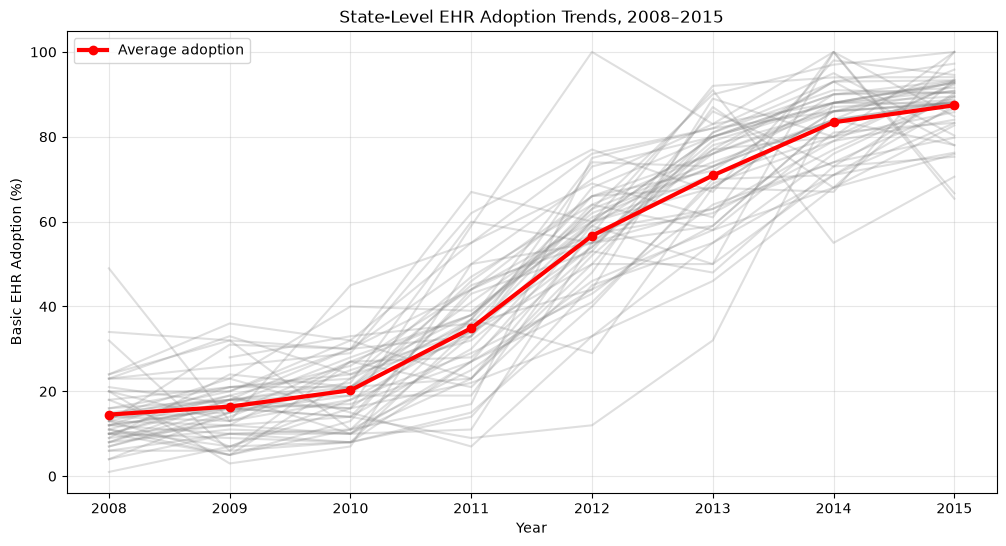

In [20]:
plt.figure(figsize=(12, 6))

for state, group in ehr_panel.groupby("region_code"):
    plt.plot(
        group["year"],
        group["ehr_adoption"] * 100,
        alpha=0.25,
        color="gray"
    )

# Overall unweighted state average
yearly_mean = ehr_panel.groupby("year")["ehr_adoption"].mean()

plt.plot(
    yearly_mean.index,
    yearly_mean.values * 100,
    color="red",
    linewidth=3,
    marker="o",
    label="Average adoption"
)

plt.xlabel("Year")
plt.ylabel("Basic EHR Adoption (%)")
plt.title("State-Level EHR Adoption Trends, 2008–2015")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [21]:
# Create a missingness indicator
ehr_panel["adoption_missing"] = (
    ehr_panel["ehr_adoption"].isna().astype(int)
)

# Confirm the panel structure
print("Regions:", ehr_panel["region_code"].nunique())
print("Years:", ehr_panel["year"].nunique())
print("Missing adoption values:",
      ehr_panel["adoption_missing"].sum())

# Save the cleaned panel
ehr_panel.to_csv(
    "ehr_cleaned_panel.csv",
    index=False
)

Regions: 51
Years: 8
Missing adoption values: 1


In [24]:
import pandas as pd

ehr = pd.read_csv("ehr_did_panel_prepared.csv")
launch = pd.read_csv("state_launch_dates.csv")

did = ehr.merge(
    launch,
    on="region_code",
    how="left",
    validate="many_to_one"
)

# Check whether any states lack verified launch dates
print(did.loc[
    did["treatment_year"].isna(),
    "region_code"
].unique())

# Do not proceed if launch dates are missing
assert did["treatment_year"].notna().all()

did["treated"] = (
    did["year"] >= did["treatment_year"]
).astype(int)

did["relative_year"] = (
    did["year"] - did["treatment_year"]
)

print(did.head(10))

<StringArray>
[]
Length: 0, dtype: str
  region_code  year  ehr_adoption launch_month  treatment_year launch_date  \
0          AK  2008      0.140000      January            2011     2011-01   
1          AK  2009      0.230000      January            2011     2011-01   
2          AK  2010      0.150000      January            2011     2011-01   
3          AK  2011      0.070000      January            2011     2011-01   
4          AK  2012      0.330000      January            2011     2011-01   
5          AK  2013      0.550000      January            2011     2011-01   
6          AK  2014      0.760000      January            2011     2011-01   
7          AK  2015      0.893634      January            2011     2011-01   
8          AL  2008      0.120000        April            2011     2011-04   
9          AL  2009      0.100000        April            2011     2011-04   

   treated  relative_year  
0        0             -3  
1        0             -2  
2        0        

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("ehr_did_with_launch_dates.csv")

print(df.shape)
print(df.head())
print(df.isnull().sum())

(408, 8)
  region_code  year  ehr_adoption launch_month launch_date  treatment_year  \
0          AK  2008          0.14      January     2011-01            2011   
1          AK  2009          0.23      January     2011-01            2011   
2          AK  2010          0.15      January     2011-01            2011   
3          AK  2011          0.07      January     2011-01            2011   
4          AK  2012          0.33      January     2011-01            2011   

   treated  relative_year  
0        0             -3  
1        0             -2  
2        0             -1  
3        1              0  
4        1              1  
region_code       0
year              0
ehr_adoption      1
launch_month      0
launch_date       0
treatment_year    0
treated           0
relative_year     0
dtype: int64


In [26]:
cohort_trends = (
    df.groupby(["treatment_year", "year"])
      .agg(
          mean_adoption=("ehr_adoption", "mean"),
          n_states=("ehr_adoption", "count")
      )
      .reset_index()
)

print(cohort_trends.head(15))

    treatment_year  year  mean_adoption  n_states
0             2011  2008       0.149024        41
1             2011  2009       0.156585        41
2             2011  2010       0.199756        41
3             2011  2011       0.338780        41
4             2011  2012       0.572195        41
5             2011  2013       0.705610        41
6             2011  2014       0.846829        41
7             2011  2015       0.875276        41
8             2012  2008       0.118571         7
9             2012  2009       0.180000         8
10            2012  2010       0.216250         8
11            2012  2011       0.357500         8
12            2012  2012       0.570000         8
13            2012  2013       0.703750         8
14            2012  2014       0.825000         8


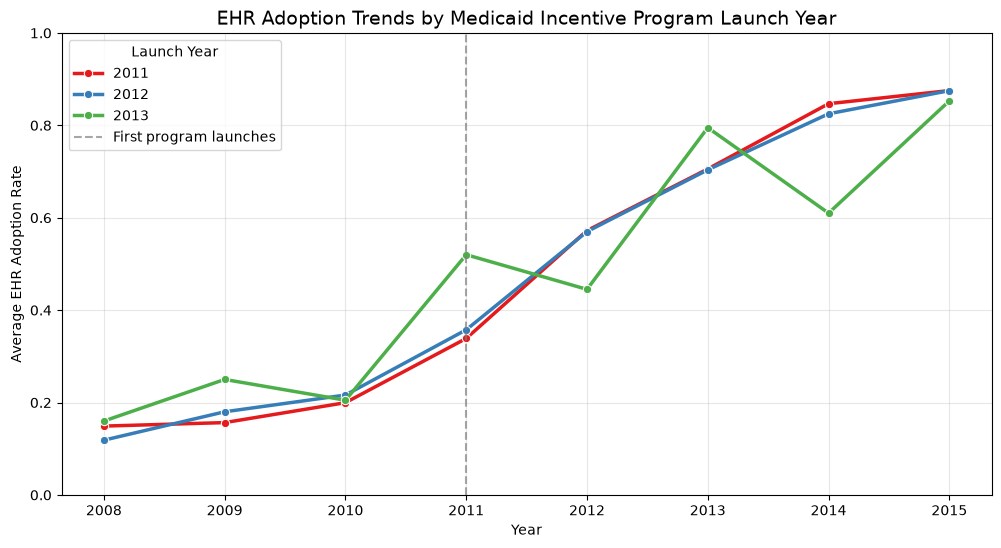

In [27]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=cohort_trends,
    x="year",
    y="mean_adoption",
    hue="treatment_year",
    marker="o",
    linewidth=2.5,
    palette="Set1"
)

plt.axvline(
    x=2011,
    color="gray",
    linestyle="--",
    alpha=0.7,
    label="First program launches"
)

plt.title(
    "EHR Adoption Trends by Medicaid Incentive Program Launch Year",
    fontsize=14
)

plt.xlabel("Year")
plt.ylabel("Average EHR Adoption Rate")
plt.xticks(range(2008, 2016))
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend(title="Launch Year")

plt.show()

In [28]:
pre = df[df["year"].between(2008, 2010)].copy()

pre_trends = (
    pre.groupby(["treatment_year", "year"])["ehr_adoption"]
       .mean()
       .unstack()
)

pre_trends["change_2008_2010"] = (
    pre_trends[2010] - pre_trends[2008]
)

print("Pre-treatment adoption trends:")
print(pre_trends.round(4))

Pre-treatment adoption trends:
year              2008    2009    2010  change_2008_2010
treatment_year                                          
2011            0.1490  0.1566  0.1998            0.0507
2012            0.1186  0.1800  0.2162            0.0977
2013            0.1600  0.2500  0.2050            0.0450


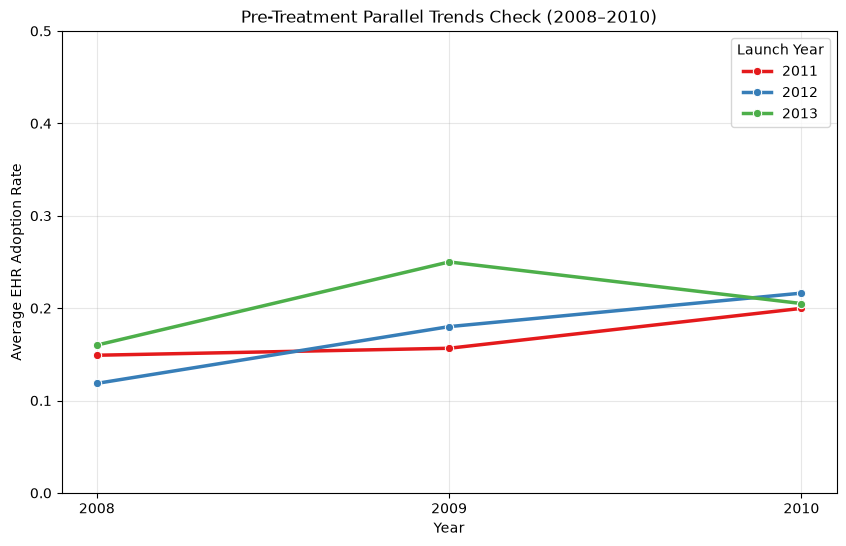

In [29]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=cohort_trends[cohort_trends["year"] <= 2010],
    x="year",
    y="mean_adoption",
    hue="treatment_year",
    marker="o",
    linewidth=2.5,
    palette="Set1"
)

plt.title("Pre-Treatment Parallel Trends Check (2008–2010)")
plt.xlabel("Year")
plt.ylabel("Average EHR Adoption Rate")
plt.xticks([2008, 2009, 2010])
plt.ylim(0, 0.5)
plt.grid(alpha=0.3)
plt.legend(title="Launch Year")
plt.show()

In [30]:
from scipy.stats import ttest_ind
import pandas as pd

# One observation per state for 2008 and 2010
baseline = df[df["year"].isin([2008, 2010])].pivot(
    index=["region_code", "treatment_year"],
    columns="year",
    values="ehr_adoption"
).reset_index()

# State-level pre-treatment change
baseline["pre_change"] = baseline[2010] - baseline[2008]

print("Pre-treatment change by cohort:")
print(
    baseline.groupby("treatment_year")["pre_change"]
    .agg(["count", "mean", "std"])
    .round(4)
)

# Compare 2011 vs 2012 launch cohorts
early = baseline.loc[
    baseline["treatment_year"] == 2011, "pre_change"
].dropna()

late = baseline.loc[
    baseline["treatment_year"] == 2012, "pre_change"
].dropna()

t_stat, p_value = ttest_ind(
    early,
    late,
    equal_var=False
)

print("\nWelch's t-test: 2011 vs 2012 cohorts")
print("t-statistic:", round(t_stat, 4))
print("p-value:", round(p_value, 6))

Pre-treatment change by cohort:
                count    mean     std
treatment_year                       
2011               41  0.0507  0.0768
2012                7  0.0814  0.0657
2013                2  0.0450  0.2475

Welch's t-test: 2011 vs 2012 cohorts
t-statistic: -1.1134
p-value: 0.294232


In [31]:
# Keep only 2011 and 2012 launch cohorts
did_sample = df[
    df["treatment_year"].isin([2011, 2012]) &
    df["year"].isin([2010, 2011])
].copy()

# Calculate mean adoption by cohort and year
did_means = (
    did_sample.groupby(["treatment_year", "year"])
    ["ehr_adoption"]
    .mean()
    .unstack()
)

print("Mean adoption by cohort:")
print(did_means.round(4))

# Change in adoption for each cohort
early_change = did_means.loc[2011, 2011] - did_means.loc[2011, 2010]
late_change = did_means.loc[2012, 2011] - did_means.loc[2012, 2010]

# Difference-in-Differences
did_estimate = early_change - late_change

print("\nEarly cohort change:", round(early_change, 4))
print("Late cohort change:", round(late_change, 4))
print("DID estimate:", round(did_estimate, 4))
print("DID in percentage points:", round(did_estimate * 100, 2))

Mean adoption by cohort:
year              2010    2011
treatment_year                
2011            0.1998  0.3388
2012            0.2162  0.3575

Early cohort change: 0.139
Late cohort change: 0.1412
DID estimate: -0.0022
DID in percentage points: -0.22


In [33]:
import statsmodels.formula.api as smf

# Use 2010 and 2011 observations from 2011 and 2012 cohorts
reg_df = df[
    df["treatment_year"].isin([2011, 2012]) &
    df["year"].isin([2010, 2011])
].copy()

# Treatment group: states that launched in 2011
reg_df["early"] = (
    reg_df["treatment_year"] == 2011
).astype(int)

# Post-treatment period: 2011
reg_df["post"] = (
    reg_df["year"] == 2011
).astype(int)

# Interaction term
reg_df["did_interaction"] = (
    reg_df["early"] * reg_df["post"]
)

# Fit DID regression with state-clustered standard errors
model = smf.ols(
    "ehr_adoption ~ early + post + did_interaction",
    data=reg_df
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": reg_df["region_code"]
    }
)

print(model.summary())

print("\nDID coefficient:",
      round(model.params["did_interaction"], 5))

print("DID p-value:",
      round(model.pvalues["did_interaction"], 5))

print("95% confidence interval:")
print(model.conf_int().loc["did_interaction"])

                            OLS Regression Results                            
Dep. Variable:           ehr_adoption   R-squared:                       0.281
Model:                            OLS   Adj. R-squared:                  0.258
Method:                 Least Squares   F-statistic:                     20.21
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           1.31e-08
Time:                        16:52:48   Log-Likelihood:                 75.493
No. Observations:                  98   AIC:                            -143.0
Df Residuals:                      94   BIC:                            -132.6
Df Model:                           3                                         
Covariance Type:              cluster                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept           0.2162      0.029     

In [34]:
import pandas as pd

# Keep only 2011 and 2012 launch cohorts
psm_df = df[
    df["treatment_year"].isin([2011, 2012])
].copy()

# Convert longitudinal observations into state-level features
psm_features = (
    psm_df[psm_df["year"].isin([2008, 2009, 2010])]
    .pivot(
        index=["region_code", "treatment_year"],
        columns="year",
        values="ehr_adoption"
    )
    .reset_index()
)

# Rename columns
psm_features = psm_features.rename(columns={
    2008: "ehr_2008",
    2009: "ehr_2009",
    2010: "ehr_2010"
})

# Treatment assignment
psm_features["treatment"] = (
    psm_features["treatment_year"] == 2011
).astype(int)

# Check missing values
print("Dataset shape:", psm_features.shape)

print("\nMissing values:")
print(psm_features.isnull().sum())

print("\nTreatment distribution:")
print(psm_features["treatment"].value_counts())

print("\nFirst five rows:")
print(psm_features.head())

Dataset shape: (49, 6)

Missing values:
year
region_code       0
treatment_year    0
ehr_2008          1
ehr_2009          0
ehr_2010          0
treatment         0
dtype: int64

Treatment distribution:
treatment
1    41
0     8
Name: count, dtype: int64

First five rows:
year region_code  treatment_year  ehr_2008  ehr_2009  ehr_2010  treatment
0             AK            2011      0.14      0.23      0.15          1
1             AL            2011      0.12      0.10      0.11          1
2             AR            2011      0.14      0.13      0.18          1
3             AZ            2011      0.14      0.20      0.32          1
4             CA            2011      0.12      0.21      0.21          1


In [35]:
psm_clean = psm_features.dropna(
    subset=["ehr_2008", "ehr_2009", "ehr_2010"]
).copy()

print("Final PSM shape:", psm_clean.shape)
print("\nTreatment distribution:")
print(psm_clean["treatment"].value_counts())

Final PSM shape: (48, 6)

Treatment distribution:
treatment
1    41
0     7
Name: count, dtype: int64


In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

features = ["ehr_2008", "ehr_2009", "ehr_2010"]

X = psm_clean[features]
y = psm_clean["treatment"]

ps_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        solver="lbfgs",
        C=1.0
    )
)

ps_model.fit(X, y)

psm_clean["propensity_score"] = (
    ps_model.predict_proba(X)[:, 1]
)

print(
    psm_clean[
        ["region_code", "treatment", "propensity_score"]
    ].head(10)
)

print("\nPropensity score summary:")
print(
    psm_clean.groupby("treatment")["propensity_score"]
    .agg(["min", "max", "mean", "std"])
    .round(4)
)

year region_code  treatment  propensity_score
0             AK          1          0.843929
1             AL          1          0.877360
2             AR          1          0.870903
3             AZ          1          0.819155
4             CA          1          0.821008
5             CO          0          0.765679
6             CT          1          0.923606
7             DE          1          0.867818
8             FL          1          0.863223
9             GA          1          0.853503

Propensity score summary:
              min     max    mean     std
treatment                                
0          0.7657  0.8942  0.8332  0.0504
1          0.7472  0.9765  0.8577  0.0449


In [37]:
# Identify common support region
treated = psm_clean[
    psm_clean["treatment"] == 1
].copy()

control = psm_clean[
    psm_clean["treatment"] == 0
].copy()

lower = max(
    treated["propensity_score"].min(),
    control["propensity_score"].min()
)

upper = min(
    treated["propensity_score"].max(),
    control["propensity_score"].max()
)

print("Common support range:", round(lower, 4), "to", round(upper, 4))

# Retain states within the overlapping range
psm_overlap = psm_clean[
    psm_clean["propensity_score"].between(lower, upper)
].copy()

print("\nStates within common support:")
print(psm_overlap["treatment"].value_counts())

print("\nStates excluded:")
print(
    psm_clean.loc[
        ~psm_clean.index.isin(psm_overlap.index),
        ["region_code", "treatment", "propensity_score"]
    ].sort_values("propensity_score")
)

Common support range: 0.7657 to 0.8942

States within common support:
treatment
1    34
0     7
Name: count, dtype: int64

States excluded:
year region_code  treatment  propensity_score
10            IA          1          0.747220
20            MI          1          0.904220
34            OK          1          0.922329
6             CT          1          0.923606
35            OR          1          0.938389
30            NM          1          0.957046
37            RI          1          0.976468


In [38]:
from scipy.optimize import linear_sum_assignment
import numpy as np
import pandas as pd

treated = psm_overlap[
    psm_overlap["treatment"] == 1
].reset_index(drop=True)

control = psm_overlap[
    psm_overlap["treatment"] == 0
].reset_index(drop=True)

# Pairwise absolute propensity score differences
distances = np.abs(
    control["propensity_score"].to_numpy()[:, None] -
    treated["propensity_score"].to_numpy()[None, :]
)

caliper = 0.05

# Find one-to-one matches, without replacement.
# Add dummy columns so controls can remain unmatched.
n_controls, n_treated = distances.shape
cost = np.concatenate(
    [
        np.where(distances <= caliper, distances, 1e6),
        np.full((n_controls, n_controls), 0.051)
    ],
    axis=1
)

rows, cols = linear_sum_assignment(cost)

matches = []

for r, c in zip(rows, cols):
    if c < n_treated and distances[r, c] <= caliper:
        matches.append({
            "control_state": control.loc[r, "region_code"],
            "treated_state": treated.loc[c, "region_code"],
            "control_score": control.loc[r, "propensity_score"],
            "treated_score": treated.loc[c, "propensity_score"],
            "distance": distances[r, c]
        })

matches_df = pd.DataFrame(matches)

print("Number of matched pairs:", len(matches_df))
print("\nMatched state pairs:")
print(matches_df.round(4).to_string(index=False))

print("\nUnmatched control states:")
print(
    sorted(
        set(control["region_code"]) -
        set(matches_df["control_state"])
    )
)

Number of matched pairs: 7

Matched state pairs:
control_state treated_state  control_score  treated_score  distance
           CO            WA         0.7657         0.7777    0.0121
           ID            LA         0.8015         0.8119    0.0105
           KS            OH         0.7812         0.7911    0.0099
           MN            KY         0.8670         0.8674    0.0004
           NE            AK         0.8458         0.8439    0.0018
           NH            MD         0.8942         0.8905    0.0037
           VA            AL         0.8774         0.8774    0.0001

Unmatched control states:
[]


In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

features = ["ehr_2008", "ehr_2009", "ehr_2010"]

# Retrieve the 7 matched treated and 7 matched control states
matched_treated = (
    psm_clean.set_index("region_code")
    .loc[matches_df["treated_state"]]
    .reset_index()
)

matched_control = (
    psm_clean.set_index("region_code")
    .loc[matches_df["control_state"]]
    .reset_index()
)

# Standardized mean difference
def smd(treated, control):
    pooled_sd = np.sqrt(
        (treated.var(ddof=1) + control.var(ddof=1)) / 2
    )
    if pooled_sd == 0:
        return np.nan
    return (treated.mean() - control.mean()) / pooled_sd

results = []

for feature in features:
    before = smd(
        psm_clean.loc[psm_clean["treatment"] == 1, feature],
        psm_clean.loc[psm_clean["treatment"] == 0, feature]
    )

    after = smd(
        matched_treated[feature],
        matched_control[feature]
    )

    results.append({
        "feature": feature,
        "before_matching": before,
        "after_matching": after
    })

balance_df = pd.DataFrame(results)

print("Covariate Balance:")
print(balance_df.round(4))

Covariate Balance:
    feature  before_matching  after_matching
0  ehr_2008           0.3819         -0.0232
1  ehr_2009          -0.1048         -0.0869
2  ehr_2010          -0.0029         -0.1044


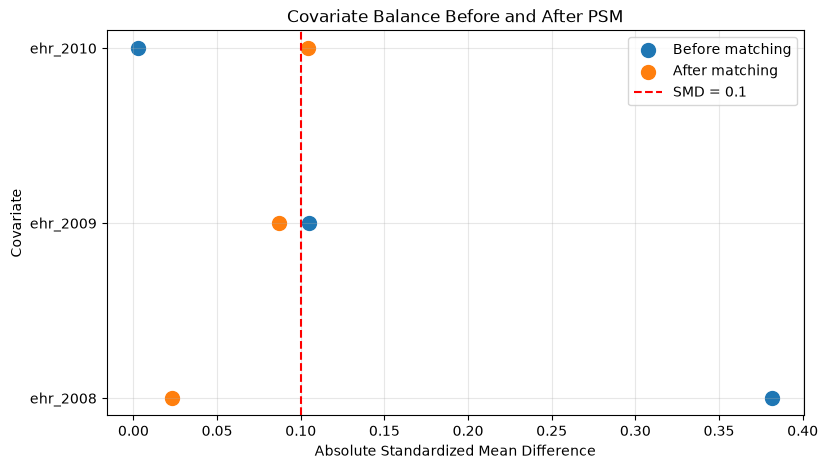

In [40]:
plt.figure(figsize=(9, 5))

plt.scatter(
    balance_df["before_matching"].abs(),
    balance_df["feature"],
    label="Before matching",
    s=100
)

plt.scatter(
    balance_df["after_matching"].abs(),
    balance_df["feature"],
    label="After matching",
    s=100
)

plt.axvline(
    0.1,
    color="red",
    linestyle="--",
    label="SMD = 0.1"
)

plt.xlabel("Absolute Standardized Mean Difference")
plt.ylabel("Covariate")
plt.title("Covariate Balance Before and After PSM")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [41]:
import pandas as pd
import numpy as np
from scipy import stats

# Calculate each state's adoption change from 2010 to 2011
outcomes = (
    df[df["year"].isin([2010, 2011])]
    .pivot(
        index="region_code",
        columns="year",
        values="ehr_adoption"
    )
)

outcomes["change"] = outcomes[2011] - outcomes[2010]

# Retrieve changes for the matched pairs
matched_did = matches_df.copy()

matched_did["treated_change"] = (
    matched_did["treated_state"]
    .map(outcomes["change"])
)

matched_did["control_change"] = (
    matched_did["control_state"]
    .map(outcomes["change"])
)

# DID for each matched pair
matched_did["pair_did"] = (
    matched_did["treated_change"] -
    matched_did["control_change"]
)

print("Matched DID results:")
print(
    matched_did[
        ["treated_state", "control_state",
         "treated_change", "control_change", "pair_did"]
    ].round(4).to_string(index=False)
)

# Average matched DID
effects = matched_did["pair_did"].dropna()

n = len(effects)
mean_effect = effects.mean()
se = effects.std(ddof=1) / np.sqrt(n)

# Exploratory paired t confidence interval
ci = stats.t.interval(
    confidence=0.95,
    df=n - 1,
    loc=mean_effect,
    scale=se
)

print("\nNumber of matched pairs:", n)
print("Average matched DID:", round(mean_effect, 5))
print("Effect in percentage points:", round(mean_effect * 100, 2))
print("95% CI (percentage points):",
      tuple(round(v * 100, 2) for v in ci))

Matched DID results:
treated_state control_state  treated_change  control_change  pair_did
           WA            CO            0.20            0.03      0.17
           LA            ID            0.10            0.00      0.10
           OH            KS            0.09            0.06      0.03
           KY            MN            0.11            0.24     -0.13
           AK            NE           -0.08            0.13     -0.21
           MD            NH            0.10            0.31     -0.21
           AL            VA            0.14            0.33     -0.19

Number of matched pairs: 7
Average matched DID: -0.06286
Effect in percentage points: -6.29
95% CI (percentage points): (np.float64(-21.07), np.float64(8.5))


In [42]:
# Retrieve matched states' pre-treatment adoption values
matched_pre = matches_df.copy()

baseline = psm_clean.set_index("region_code")

for year in [2008, 2009, 2010]:
    matched_pre[f"treated_{year}"] = (
        matched_pre["treated_state"]
        .map(baseline[f"ehr_{year}"])
    )

    matched_pre[f"control_{year}"] = (
        matched_pre["control_state"]
        .map(baseline[f"ehr_{year}"])
    )

# Calculate pre-treatment changes
matched_pre["treated_pre_change"] = (
    matched_pre["treated_2010"] -
    matched_pre["treated_2008"]
)

matched_pre["control_pre_change"] = (
    matched_pre["control_2010"] -
    matched_pre["control_2008"]
)

matched_pre["pre_trend_difference"] = (
    matched_pre["treated_pre_change"] -
    matched_pre["control_pre_change"]
)

print("Matched pre-treatment trend differences:")
print(
    matched_pre[
        ["treated_state", "control_state",
         "treated_pre_change",
         "control_pre_change",
         "pre_trend_difference"]
    ].round(4).to_string(index=False)
)

print("\nAverage pre-treatment trend difference (pp):")
print(round(
    matched_pre["pre_trend_difference"].mean() * 100, 2
))

Matched pre-treatment trend differences:
treated_state control_state  treated_pre_change  control_pre_change  pre_trend_difference
           WA            CO                0.12                0.17                 -0.05
           LA            ID                0.09                0.12                 -0.03
           OH            KS                0.18                0.15                  0.03
           KY            MN                0.07                0.05                  0.02
           AK            NE                0.01                0.02                 -0.01
           MD            NH                0.07                0.00                  0.07
           AL            VA               -0.01                0.06                 -0.07

Average pre-treatment trend difference (pp):
-0.57


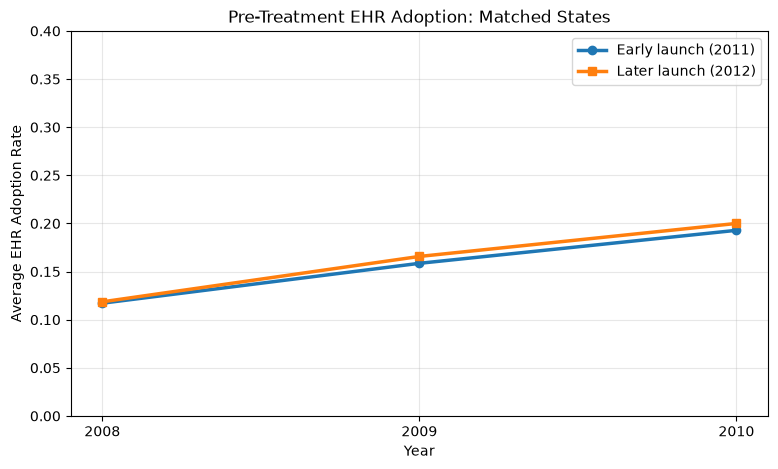

In [43]:
import pandas as pd
import matplotlib.pyplot as plt

years = [2008, 2009, 2010]

treated_means = [
    matched_pre[f"treated_{year}"].mean()
    for year in years
]

control_means = [
    matched_pre[f"control_{year}"].mean()
    for year in years
]

plt.figure(figsize=(9, 5))

plt.plot(
    years, treated_means,
    marker="o", linewidth=2.5,
    label="Early launch (2011)"
)

plt.plot(
    years, control_means,
    marker="s", linewidth=2.5,
    label="Later launch (2012)"
)

plt.title("Pre-Treatment EHR Adoption: Matched States")
plt.xlabel("Year")
plt.ylabel("Average EHR Adoption Rate")
plt.xticks(years)
plt.ylim(0, 0.4)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

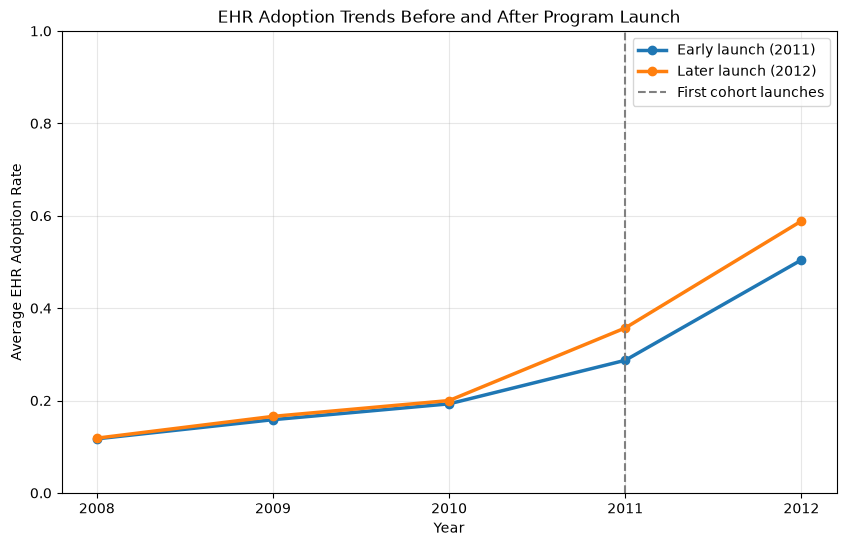

In [44]:
import matplotlib.pyplot as plt
import pandas as pd

# Get matched states
treated_states = matches_df["treated_state"].tolist()
control_states = matches_df["control_state"].tolist()

# Keep matched states, 2008–2012
plot_df = df[
    df["region_code"].isin(treated_states + control_states) &
    df["year"].between(2008, 2012)
].copy()

plot_df["group"] = plot_df["region_code"].apply(
    lambda x: "Early launch (2011)"
    if x in treated_states
    else "Later launch (2012)"
)

# Average adoption by group and year
trend_data = (
    plot_df.groupby(["group", "year"])["ehr_adoption"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 6))

for group, data in trend_data.groupby("group"):
    plt.plot(
        data["year"],
        data["ehr_adoption"],
        marker="o",
        linewidth=2.5,
        label=group
    )

plt.axvline(
    2011,
    color="gray",
    linestyle="--",
    label="First cohort launches"
)

plt.title("EHR Adoption Trends Before and After Program Launch")
plt.xlabel("Year")
plt.ylabel("Average EHR Adoption Rate")
plt.xticks(range(2008, 2013))
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

ML INTEGRATION


In [46]:
import ollama

MODEL = "qwen2.5:3b"

response = ollama.chat(
    model=MODEL,
    messages=[
        {
            "role": "system",
            "content": (
                "You are a research assistant specializing in "
                "healthcare analytics, causal inference, "
                "Difference-in-Differences, and Propensity Score Matching."
            )
        },
        {
            "role": "user",
            "content": (
                "Explain the difference between Difference-in-Differences "
                "and Propensity Score Matching in three sentences."
            )
        }
    ]
)

print(response["message"]["content"])

Difference-in-Differences is a quasi-experimental method used to estimate the causal effect of an intervention by comparing changes in outcomes over time between a group that received the intervention (or treatment) and a group that did not. Propensity Score Matching, on the other hand, aims to reduce bias in observational studies by creating comparable groups that received and did not receive an intervention, by matching units based on the probability of receiving the intervention.


In [47]:
import json

research_knowledge = {
    "project": {
        "title": "EHR Adoption and Medicaid Incentive Program Evaluation",
        "research_question": (
            "Did earlier state Medicaid EHR incentive program launches "
            "lead to greater EHR adoption?"
        )
    },

    "dataset": {
        "source": "ONC Health IT Adoption and Use dataset",
        "unit_of_analysis": "State-year",
        "years": "2008–2015",
        "regions": 51,
        "observations": 408,
        "outcome": "Proportion of hospitals with basic EHR adoption",
        "missing_values": "Nevada 2008 adoption is missing"
    },

    "policy": {
        "name": "Medicaid EHR Incentive Program",
        "source": "CMS State EHR Incentive Program Web Resources Guide, January 2017",
        "launch_cohorts": {
            "2011": 41,
            "2012": 8,
            "2013": 2
        },
        "treatment_definition": "State Medicaid program registration launch year"
    },

    "did_analysis": {
        "comparison": "2011 launch states versus 2012 launch states",
        "pre_year": 2010,
        "post_year": 2011,
        "treated_states": 41,
        "control_states": 8,
        "estimate_percentage_points": -0.22,
        "p_value": 0.9641,
        "confidence_interval_percentage_points": [-9.91, 9.46],
        "interpretation": (
            "The early-launch cohort had approximately 0.22 percentage "
            "points less adoption growth than the later-launch cohort. "
            "The difference was not statistically significant."
        )
    },

    "psm_analysis": {
        "method": "Logistic regression propensity scores and one-to-one matching",
        "covariates": ["EHR adoption 2008", "EHR adoption 2009", "EHR adoption 2010"],
        "matched_pairs": 7,
        "matching_caliper": 0.05,
        "matching_replacement": False,
        "matched_did_percentage_points": -6.29,
        "matched_did_ci_percentage_points": [-21.07, 8.50],
        "pre_treatment_trend_difference_percentage_points": -0.57,
        "interpretation": (
            "Matched early-launch states had 6.29 percentage points "
            "less adoption growth than matched later-launch states "
            "during 2010–2011. The confidence interval includes zero."
        )
    },

    "limitations": [
        "Observational analysis does not establish causality.",
        "Parallel trends cannot be proven from observed pre-treatment data.",
        "Only seven matched state pairs were available.",
        "Propensity score matching used only historical EHR adoption variables.",
        "National HITECH policies affected states in both groups.",
        "Annual EHR adoption data may not align with exact program launch months.",
        "Matched and unmatched DID estimates target different state populations.",
        "The confidence intervals do not rule out meaningful positive or negative effects."
    ]
}

with open("ehr_research_knowledge.json", "w") as f:
    json.dump(research_knowledge, f, indent=4)

print("Research knowledge base created successfully!")

Research knowledge base created successfully!


In [48]:
with open("ehr_research_knowledge.json", "r") as f:
    knowledge = json.load(f)

print("Project:", knowledge["project"]["title"])
print("Research question:", knowledge["project"]["research_question"])
print("DID estimate:", knowledge["did_analysis"]["estimate_percentage_points"])
print("Matched DID:", knowledge["psm_analysis"]["matched_did_percentage_points"])
print("Limitations:", len(knowledge["limitations"]))

Project: EHR Adoption and Medicaid Incentive Program Evaluation
Research question: Did earlier state Medicaid EHR incentive program launches lead to greater EHR adoption?
DID estimate: -0.22
Matched DID: -6.29
Limitations: 8


In [49]:
import json
import ollama

MODEL = "qwen2.5:3b"

with open("ehr_research_knowledge.json", "r") as f:
    knowledge = json.load(f)

research_context = json.dumps(knowledge, indent=2)

print("Knowledge base loaded successfully!")

Knowledge base loaded successfully!


In [50]:
def ask_ehr_assistant(question):

    system_prompt = """
    You are an AI Research Assistant specializing in:
    - Healthcare analytics
    - Electronic Health Records (EHR)
    - Difference-in-Differences (DID)
    - Propensity Score Matching (PSM)
    - Statistical inference and causal research

    You are given a structured research knowledge base.

    RULES:
    1. Use the provided research evidence for project-specific claims.
    2. Never invent statistical results, p-values, or sample sizes.
    3. Clearly distinguish association from causation.
    4. Explain statistical findings in clear academic language.
    5. If a question cannot be answered using the evidence,
       explicitly state that the information is unavailable.
    6. Do not interpret a nonsignificant result as proof of no effect.
    7. Include relevant numerical results when answering.
    8. Keep answers concise but scientifically meaningful.
    """

    user_prompt = f"""
    RESEARCH KNOWLEDGE BASE:
    {research_context}

    QUESTION:
    {question}

    Answer using the research evidence above.
    """

    response = ollama.chat(
        model=MODEL,
        messages=[
            {
                "role": "system",
                "content": system_prompt
            },
            {
                "role": "user",
                "content": user_prompt
            }
        ],
        options={
            "temperature": 0
        }
    )

    return response["message"]["content"]

In [51]:
question = (
    "Did earlier Medicaid EHR incentive program launches "
    "significantly improve EHR adoption?"
)

answer = ask_ehr_assistant(question)

print("QUESTION:", question)
print("\nANSWER:\n", answer)

QUESTION: Did earlier Medicaid EHR incentive program launches significantly improve EHR adoption?

ANSWER:
 The research evidence suggests that earlier Medicaid EHR incentive program launches did not significantly improve EHR adoption. The Difference-in-Differences (DID) analysis found that states with an earlier launch of the Medicaid EHR Incentive Program had approximately 0.22 percentage points less adoption growth than states with a later launch, with a p-value of 0.9641. This indicates that the difference was not statistically significant. The Propensity Score Matching (PSM) analysis also showed a non-significant result, with a matched DID estimate of -6.29 percentage points, and a confidence interval that includes zero. Both methods suggest that the early launch of the program did not lead to a meaningful improvement in EHR adoption.


In [52]:
test_questions = [
    "How many states were included in the original EHR dataset?",
    "What was the matched DID estimate?",
    "Did propensity score matching improve covariate balance?",
    "What were the limitations of the study?",
    "What was the average hospital waiting time in 2015?"
]

for question in test_questions:
    print("=" * 70)
    print("QUESTION:", question)
    print("ANSWER:", ask_ehr_assistant(question))
    print()

QUESTION: How many states were included in the original EHR dataset?
ANSWER: The original EHR dataset included 51 states.

QUESTION: What was the matched DID estimate?
ANSWER: The matched Difference-in-Differences (DID) estimate was -6.29 percentage points. The 95% confidence interval for this estimate is -21.07 to 8.5 percentage points.

QUESTION: Did propensity score matching improve covariate balance?
ANSWER: The propensity score matching (PSM) analysis did not conclusively demonstrate an improvement in covariate balance. The matched pairs analysis resulted in a pre-treatment trend difference of -0.57 percentage points, which is not statistically significant (95% confidence interval: -21.07 to 8.5). This suggests that the historical EHR adoption variables used in the PSM did not sufficiently balance the covariates between the matched early-launch states and the matched later-launch states.

QUESTION: What were the limitations of the study?
ANSWER: The study had several limitations:


In [54]:
import json
from pathlib import Path
from pypdf import PdfReader

with open("ehr_research_knowledge.json", "r") as f:
    knowledge = json.load(f)

documents = []

# Convert research findings into searchable documents
for section, content in knowledge.items():
    documents.append({
        "id": f"research_{section}",
        "text": json.dumps(content, indent=2),
        "source": f"Research analysis: {section}"
    })

# Extract the official CMS policy document
pdf_path = Path(
    "State EHR Incentive Program Web Resources Guide Jan 2017.pdf"
)

reader = PdfReader(str(pdf_path))

for page_number, page in enumerate(reader.pages, start=1):
    text = page.extract_text()

    if text and text.strip():
        documents.append({
            "id": f"cms_page_{page_number}",
            "text": text,
            "source": f"CMS EHR Guide, page {page_number}"
        })

print("Documents loaded:", len(documents))

Documents loaded: 10


In [55]:
import chromadb
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

client = chromadb.PersistentClient(
    path="./ehr_chroma_db"
)

collection = client.get_or_create_collection(
    name="ehr_research"
)

texts = [doc["text"] for doc in documents]

embeddings = embedding_model.encode(
    texts,
    normalize_embeddings=True
).tolist()

collection.upsert(
    ids=[doc["id"] for doc in documents],
    documents=texts,
    embeddings=embeddings,
    metadatas=[
        {"source": doc["source"]}
        for doc in documents
    ]
)

print("Documents indexed:", collection.count())

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1108 17:09:29.163000 47992 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6743.46it/s]
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


Documents indexed: 10


In [56]:
def retrieve_evidence(question, top_k=3):

    query_embedding = embedding_model.encode(
        [question],
        normalize_embeddings=True
    ).tolist()

    results = collection.query(
        query_embeddings=query_embedding,
        n_results=min(top_k, collection.count())
    )

    evidence = []

    for text, metadata in zip(
        results["documents"][0],
        results["metadatas"][0]
    ):
        evidence.append({
            "source": metadata["source"],
            "text": text
        })

    return evidence


question = "What was the matched DID estimate?"

retrieved = retrieve_evidence(question)

for item in retrieved:
    print("\nSOURCE:", item["source"])
    print("TEXT:", item["text"][:700])
    print("-" * 60)


SOURCE: Research analysis: limitations
TEXT: [
  "Observational analysis does not establish causality.",
  "Parallel trends cannot be proven from observed pre-treatment data.",
  "Only seven matched state pairs were available.",
  "Propensity score matching used only historical EHR adoption variables.",
  "National HITECH policies affected states in both groups.",
  "Annual EHR adoption data may not align with exact program launch months.",
  "Matched and unmatched DID estimates target different state populations.",
  "The confidence intervals do not rule out meaningful positive or negative effects."
]
------------------------------------------------------------

SOURCE: Research analysis: psm_analysis
TEXT: {
  "method": "Logistic regression propensity scores and one-to-one matching",
  "covariates": [
    "EHR adoption 2008",
    "EHR adoption 2009",
    "EHR adoption 2010"
  ],
  "matched_pairs": 7,
  "matching_caliper": 0.05,
  "matching_replacement": false,
  "matched_did_percent

In [59]:
import ollama

def ask_ehr_rag(question, top_k=3):

    retrieved_docs = retrieve_evidence(
        question,
        top_k=top_k
    )

    context = "\n\n".join(
        f"[Source {i}: {doc['source']}]\n{doc['text']}"
        for i, doc in enumerate(retrieved_docs, start=1)
    )

    system_prompt = """
    You are a rigorous statistical research assistant.

    Answer using ONLY the retrieved evidence.

    CRITICAL RULES:

    1. Treat unmatched DID and matched DID as separate analyses.

    2. Never use a p-value, confidence interval, or sample size
       from one analysis to describe another analysis.

    3. The p-value 0.9641 belongs ONLY to unmatched DID.

    4. The matched DID analysis has a 95% confidence interval,
       but no separately reported p-value in the knowledge base.

    5. If a statistic is unavailable for the requested analysis,
       explicitly state that it is unavailable.

    6. A confidence interval containing zero indicates that
       the estimate is not statistically significant at the
       conventional 5% level, assuming a valid two-sided 95% CI.

    7. Never interpret nonsignificance as proof of no effect.

    8. Cite the exact source supporting each numerical claim.

    9. Do not cite unrelated sources merely because they
       were retrieved.

    10. Clearly distinguish findings from causal conclusions.
    """

    response = ollama.chat(
        model="qwen2.5:3b",
        messages=[
            {
                "role": "system",
                "content": system_prompt
            },
            {
                "role": "user",
                "content": (
                    f"RETRIEVED EVIDENCE:\n{context}\n\n"
                    f"QUESTION:\n{question}"
                )
            }
        ],
        options={"temperature": 0}
    )

    return {
        "question": question,
        "answer": response["message"]["content"],
        "sources": [
            doc["source"] for doc in retrieved_docs
        ]
    }

In [60]:
question = "What was the matched DID estimate and was it statistically significant?"

result = ask_ehr_rag(question)

print("QUESTION:")
print(result["question"])

print("\nRAG ANSWER:")
print(result["answer"])

print("\nRETRIEVED SOURCES:")
for source in result["sources"]:
    print("-", source)

QUESTION:
What was the matched DID estimate and was it statistically significant?

RAG ANSWER:
The matched DID estimate was -6.29 percentage points, with a 95% confidence interval of -21.07 to 8.5. The confidence interval contains zero, indicating that the estimate is not statistically significant at the conventional 5% level. Therefore, the matched DID estimate is not statistically significant.

RETRIEVED SOURCES:
- Research analysis: limitations
- Research analysis: psm_analysis
- Research analysis: did_analysis
